In [88]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf     # Builds and trains the neural network

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping

# Create the dataset

In [89]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [90]:
X.shape

(1000, 2)

In [91]:
y.shape

(1000,)

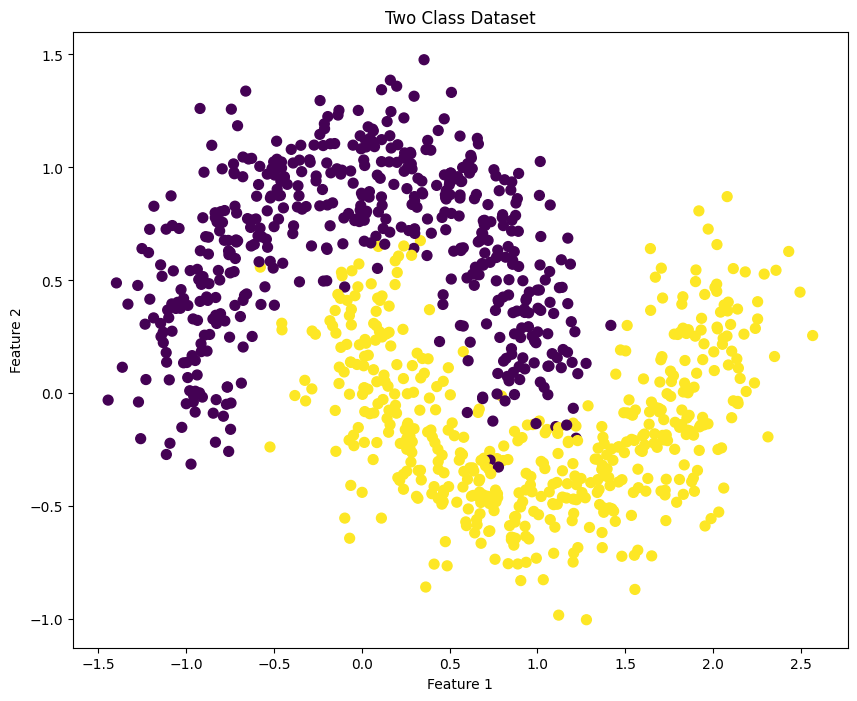

In [92]:
plt.figure(figsize=(10, 8))

plt.scatter(X[:, 0], X[:, 1], c=y, s=50)
plt.title("Two Class Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Split the data into training and testing

In [93]:
# We are splitting the dataset into three separate parts, and each part has a different job: Train data, validation data, test data.
# The validation and test data both contain unseen data, but the validation data helps you make decisions during development. The test set is reserved for the final evaluation

In [94]:
# Separate the test set

# X, y --> The complete dataset: input and their labels
# test_size --> Put 20% of the examples into the test set
# random_state --> Make the random split reproducible, so running it again with the same data and settings gives the same split
# stratify = y -> Keep the proportion of the two classes approx the same in both parts

# X_train_val --> the input features for the 800 rows we will split further
# y_train_val --> their corresponding labels
# X_test --> the input features for the 200 test samples
# y_test --> their corresponding labels
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [95]:
# Now split the remaining 800 examples. Notice, we are no longer passing X, and y. Instead, we pass X_train_val, and y_train val which contain only the 800 examples after the previous splitting

# test_size = 0.25 means 25% of these 800 examples will go into the validation set. The remaining 600 examples will go into the training set
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val)

In [96]:
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

Training examples: 600
Validation examples: 200
Test examples: 200


# Scale the features

In [97]:
# StandardScaler standardizes the features so they have approx zero mean and unit variance.
scaler = StandardScaler()

In [98]:
# We only apply fit_transform() on the training data. The validation and test data are transformed using the same scaler without fitting it again. This prevents information from those datasets from leaking into preprocessing.
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Build the neural network

In [99]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(2,)),
    Dense(64, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

In [100]:
# Model Configuration
model.compile(metrics=["accuracy"], optimizer="adam", loss="binary_crossentropy")

In [101]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

In [102]:
# Our network has:
# - Input: 2 features per example.
# - Hidden layer 1: 64 neurons with ReLU activation.
# - Hidden layer 2: 64 neurons with ReLU activation.
# - Output: 1 sigmoid neuron that predicts the probability of class 1.
# The compile() method configures the learning process:
# - adam: updates the weights using gradients.
# - binary_crossentropy: measures prediction error for binary classification.
# - accuracy: tracks the fraction of correctly classified examples.
# So far, we have built and configured the network, but we haven't trained it.

# Define early stopping

In [103]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=0
)

In [104]:
# monitor --> Keras monitors the loss calculated on the validation set after each epoch
# patience --> If validation loss fails to improve for 15 consecutive epochs, training stops. If it improves during that period, the waiting counter resets.
# restore_best_weights --> Suppose the lowest validation loss occurred at epoch 35, but the model continued training until epoch 45 before stopping. Keras restores the weights from epoch 35. This means the model doesn't simply keep the weights from the final epoch; it restores the weights from the best epoch according to the monitored metric.

# Train the model with early stopping

What happens now?
1. The model trains on the training set.
2. At the end of each epoch, Keras evaluates validation loss.
3. If validation loss improves, Keras records the better result.
4. If it fails to improve for 15 consecutive epochs, training stops.
5. The best recorded weights are restored.
The model may finish before epoch 200. It can also reach the full 200 epochs if the stopping condition isn't met.

In [105]:
history = model.fit(
    x = X_train,        # Training inputs and their correct labels
    y = y_train,
    epochs = 200,       # Max number of epochs, not required to complete all 200
    batch_size= 32,     # Processes 32 samples in batch, except possibly the last one
    validation_data=(X_val, y_val), # Measures performance on separate validation examples
    callbacks=[early_stopping], # Activates the early stopping rule
    verbose=1
)

Epoch 1/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8367 - loss: 0.5867 - val_accuracy: 0.8300 - val_loss: 0.5010
Epoch 2/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8650 - loss: 0.4213 - val_accuracy: 0.8300 - val_loss: 0.3854
Epoch 3/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8633 - loss: 0.3268 - val_accuracy: 0.8250 - val_loss: 0.3463
Epoch 4/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8667 - loss: 0.2946 - val_accuracy: 0.8300 - val_loss: 0.3417
Epoch 5/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8733 - loss: 0.2843 - val_accuracy: 0.8300 - val_loss: 0.3383
Epoch 6/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8733 - loss: 0.2773 - val_accuracy: 0.8350 - val_loss: 0.3323
Epoch 7/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8750 - loss: 0.2702 - val_accuracy: 0.8350 - val_loss: 0.3250
Epoch 8/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8783 - loss: 0.2625 - val_accuracy: 0.8550 - v

# Check when training stopped

In [106]:
epochs_completed = len(history.history["loss"])
epochs_completed

116

In [107]:
best_epoch = (
    np.argmin(history.history["val_loss"]) + 1
)

In [108]:
print("Epochs completed:", epochs_completed)
print("Best epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"])
)

Epochs completed: 116
Best epoch: 101
Best validation loss: 0.07985091209411621


# Visualize the loss curves

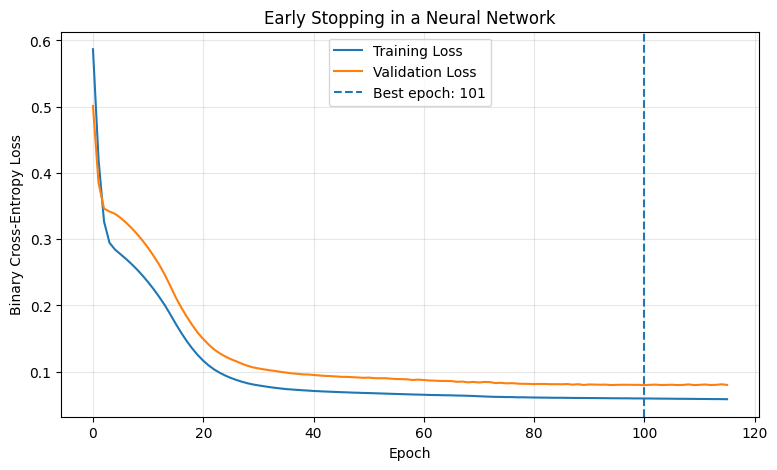

In [109]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Early Stopping in a Neural Network")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Evaluate the final model

In [110]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss: 0.0325
Test Accuracy: 98.50%
